In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

df = pd.read_csv(r"C:\Users\saqli\Downloads\workspace\Employee-Attrition-Project\data\employee_attrition_clean.csv")

X = df.drop(
    columns=["EmployeeID", "Attrition", "LastPromotionYears"]
)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", X.columns.tolist())

Training rows: 800
Testing rows: 200
Features: ['TotalMonthsOfExp', 'TotalOrgsWorked', 'MonthsInOrg', 'LastPayIncrementBand', 'AverageFeedback']


In [5]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")
print("Number of trees:", len(rf_model.estimators_))

Random Forest training completed.
Number of trees: 200


In [6]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Probability_Class_1": y_prob
})

print(results.head(10).round(3))

   Actual  Predicted  Probability_Class_1
0       0          0                0.205
1       0          1                0.630
2       0          0                0.015
3       0          0                0.035
4       0          0                0.165
5       0          1                0.690
6       1          0                0.280
7       0          1                0.780
8       0          0                0.245
9       0          0                0.025


In [7]:
print("Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 3))

Accuracy: 63.5 %
Balanced accuracy: 0.473

Confusion Matrix:
[[119  35]
 [ 38   8]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.77      0.77       154
           1       0.19      0.17      0.18        46

    accuracy                           0.64       200
   macro avg       0.47      0.47      0.47       200
weighted avg       0.63      0.64      0.63       200

ROC-AUC: 0.465


TotalMonthsOfExp        0.340706
MonthsInOrg             0.330323
TotalOrgsWorked         0.115206
LastPayIncrementBand    0.113774
AverageFeedback         0.099992
dtype: float64


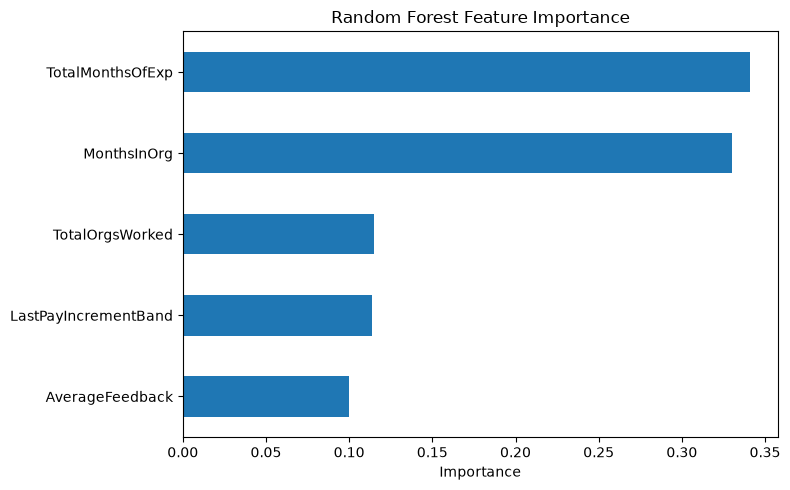

In [8]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

print(importance.sort_values(ascending=False))

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Train Logistic Regression using the same features and split
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [10]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

comparison = []

for name, clf in models.items():
    predictions = clf.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Class 1 Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Class 1 F1": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.round(3))

                 Model  Accuracy  Balanced Accuracy  Class 1 Recall  \
0  Logistic Regression     0.520              0.536           0.565   
1        Random Forest     0.635              0.473           0.174   

   Class 1 F1  
0       0.351  
1       0.180  
